## Amenities Accessibility — Data Processing Methodology

This section documents the original data preparation, geocoding,
and distance calculation process.

Residential projects were geocoded using OneMap, with street-level
fallbacks where needed. Nearest amenity distances were calculated
using BallTree and the Haversine metric.

The geocoding and distance calculations have already been completed.
Precomputed results are available in the group's GitHub repository.

**Note:** The original calculation requires the source amenity
datasets and is included for methodology reference rather than
automatic re-execution.

```python
# DAO2702 — Accessibility: Amenities Analysis
# Steps 1–5: Data preparation, geocoding and distance calculation

import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests

from shapely.geometry import shape
from sklearn.neighbors import BallTree

# ==========================================
# 1. FILES AND RESIDENTIAL PROJECTS
# ==========================================

BASE = Path('/content')
OUT = Path('/content/drive/MyDrive/DAO2702_Amenities')
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    'properties': 'properties2025_cleaned.csv',
    'hawker': 'HawkerCentresGEOJSON.geojson',
    'supermarket': 'ListofSupermarketLicences.csv',
    'mall': 'shopping_malls.geojson',
    'park': 'parks.geojson',
    'healthcare': 'hospitals.geojson'
}

for key, filename in FILES.items():
    if not (BASE / filename).exists():
        raise FileNotFoundError(
            f'Missing file: {filename}. Please upload it first.'
        )

raw = pd.read_csv(BASE / FILES['properties'])

required = ['project', 'street', 'district', 'segment']

projects = (
    raw.loc[
        raw['segment'].isin(['CCR', 'RCR', 'OCR']),
        required
    ]
    .dropna(subset=['project', 'street'])
    .drop_duplicates()
    .reset_index(drop=True)
)

projects['key'] = projects[required].astype(str).agg('|'.join, axis=1)

projects.to_csv(OUT / 'sample_projects.csv', index=False)

print('Total projects:', len(projects), flush=True)
print(projects['segment'].value_counts(), flush=True)


# ==========================================
# 2. READ EXTERNAL GEOJSON DATA
# ==========================================

def geojson_points(path):
    with open(path, encoding='utf-8') as f:
        data = json.load(f)

    features = data.get('features', [])
    output = []

    for feature in features:
        geometry = feature.get('geometry')

        if not geometry:
            continue

        try:
            g = shape(geometry)

            if g.is_empty:
                continue

            point = (
                g if g.geom_type == 'Point'
                else g.representative_point()
            )

            lat = float(point.y)
            lon = float(point.x)

            # Initial bounding-box filter
            if 1.15 <= lat <= 1.48 and 103.60 <= lon <= 104.10:
                props = feature.get('properties') or {}

                output.append({
                    'lat': lat,
                    'lon': lon,
                    'name': str(props.get('name', ''))
                })

        except Exception:
            continue

    return (
        pd.DataFrame(
            output,
            columns=['lat', 'lon', 'name']
        )
        .drop_duplicates(subset=['lat', 'lon'])
        .reset_index(drop=True)
    )


hawker = geojson_points(BASE / FILES['hawker'])
mall = geojson_points(BASE / FILES['mall'])
park = geojson_points(BASE / FILES['park'])
healthcare = geojson_points(BASE / FILES['healthcare'])

super_raw = pd.read_csv(
    BASE / FILES['supermarket'],
    dtype=str,
    encoding='utf-8-sig'
)

postal_cols = [
    c for c in super_raw.columns
    if 'postal' in c.lower()
]

if not postal_cols:
    raise ValueError(
        'Cannot find supermarket postal-code column.'
    )

postal_col = postal_cols[0]

super_codes = (
    super_raw[postal_col]
    .fillna('')
    .astype(str)
    .str.extract(r'(\d{6})')[0]
    .dropna()
    .drop_duplicates()
    .tolist()
)

print('Hawker centres:', len(hawker), flush=True)
print('Shopping malls:', len(mall), flush=True)
print('Parks:', len(park), flush=True)
print('Healthcare locations:', len(healthcare), flush=True)
print('Supermarket postal codes:', len(super_codes), flush=True)


# ==========================================
# 3. GEOCODING WITH GOOGLE DRIVE CACHE
# ==========================================

session = requests.Session()

session.headers.update({
    'User-Agent': 'DAO2702-Student-Amenities-Analysis/1.0'
})

CACHE = OUT / 'geocoding_cache.csv'

if CACHE.exists():
    cache = pd.read_csv(CACHE, dtype={'query': str})
    cache = cache.drop_duplicates('query', keep='last')
else:
    cache = pd.DataFrame(
        columns=['query', 'lat', 'lon', 'source']
    )

lookup = {
    row['query']: (
        row['lat'],
        row['lon'],
        row['source']
    )
    for _, row in cache.iterrows()
}


def search_onemap(query):
    url = 'https://www.onemap.gov.sg/api/common/elastic/search'

    for attempt in range(3):
        try:
            response = session.get(
                url,
                params={
                    'searchVal': query,
                    'returnGeom': 'Y',
                    'getAddrDetails': 'Y',
                    'pageNum': 1
                },
                timeout=20
            )

            if response.status_code == 429:
                time.sleep(3 * (attempt + 1))
                continue

            response.raise_for_status()

            results = response.json().get('results', [])

            if results:
                result = results[0]

                lat = float(result['LATITUDE'])
                lon = float(result['LONGITUDE'])

                if (
                    1.15 <= lat <= 1.48
                    and 103.60 <= lon <= 104.10
                ):
                    return lat, lon

            return np.nan, np.nan

        except (requests.RequestException, ValueError, KeyError):
            time.sleep(2 * (attempt + 1))

    return np.nan, np.nan


def geocode(query):
    query = str(query).strip()

    if query in lookup:
        lat, lon, _ = lookup[query]

        return (
            float(lat) if pd.notna(lat) else np.nan,
            float(lon) if pd.notna(lon) else np.nan
        )

    lat, lon = search_onemap(query)

    lookup[query] = (lat, lon, 'OneMap')

    return lat, lon


def save_cache():
    records = [
        {
            'query': key,
            'lat': value[0],
            'lon': value[1],
            'source': value[2]
        }
        for key, value in lookup.items()
    ]

    pd.DataFrame(records).to_csv(CACHE, index=False)


# Geocode residential projects
coordinates = []

for i, row in projects.iterrows():

    lat, lon = geocode(row['project'])
    method = 'project'

    if not np.isfinite(lat):
        lat, lon = geocode(row['street'])
        method = 'street_fallback'

    coordinates.append((lat, lon, method))

    if (i + 1) % 50 == 0:
        save_cache()

        print(
            f'Geocoded projects: {i + 1}/{len(projects)}',
            flush=True
        )

    time.sleep(0.15)

save_cache()

projects[['lat', 'lon', 'geocode_method']] = (
    pd.DataFrame(coordinates, index=projects.index)
)

projects.to_csv(
    OUT / 'residential_projects_geocoded.csv',
    index=False
)

print(
    'Successfully geocoded:',
    projects['lat'].notna().sum(),
    '/',
    len(projects),
    flush=True
)


# Geocode supermarket postal codes
supermarket_coordinates = []

for i, code in enumerate(super_codes):

    lat, lon = geocode(code)

    if np.isfinite(lat):
        supermarket_coordinates.append({
            'lat': lat,
            'lon': lon,
            'name': code
        })

    if (i + 1) % 50 == 0:
        save_cache()

        print(
            f'Supermarket postal codes: {i + 1}/{len(super_codes)}',
            flush=True
        )

    time.sleep(0.15)

save_cache()

supermarket = (
    pd.DataFrame(
        supermarket_coordinates,
        columns=['lat', 'lon', 'name']
    )
    .drop_duplicates(subset=['lat', 'lon'])
)


# ==========================================
# 4. COMBINE FACILITY CATEGORIES
# ==========================================

facilities = {
    'Food': hawker,

    'Shopping': (
        pd.concat(
            [mall, supermarket],
            ignore_index=True
        )
        .drop_duplicates(subset=['lat', 'lon'])
    ),

    'Leisure': park,

    'Healthcare': healthcare
}

print('\nFacility counts:', flush=True)

for category, data in facilities.items():
    print(category, len(data), flush=True)

if any(len(data) == 0 for data in facilities.values()):
    raise ValueError(
        'One or more facility categories are empty.'
    )


# ==========================================
# 5. CALCULATE NEAREST AMENITY DISTANCES
# ==========================================

valid = projects.dropna(
    subset=['lat', 'lon']
).copy()

for category, data in facilities.items():

    tree = BallTree(
        np.radians(
            data[['lat', 'lon']].to_numpy(float)
        ),
        metric='haversine'
    )

    distances, indices = tree.query(
        np.radians(
            valid[['lat', 'lon']].to_numpy(float)
        ),
        k=1
    )

    valid[category + '_km'] = (
        distances[:, 0] * 6371.0088
    )


# Save individual project distances
valid.to_csv(
    OUT / 'amenities_project_distances.csv',
    index=False
)


# Calculate median distances by region
summary = (
    valid.groupby('segment')[
        [category + '_km' for category in facilities]
    ]
    .median()
    .reindex(['CCR', 'RCR', 'OCR'])
)

summary.columns = list(facilities)

summary.to_csv(
    OUT / 'amenities_median_distances_km.csv'
)

print('\nMedian distances (km):', flush=True)
print(summary.round(3), flush=True)

print('\nSTEPS 1–5 COMPLETED!', flush=True)
print('Results saved to:', OUT, flush=True)
```

In [6]:

import pandas as pd

# Load saved results from the group GitHub repository
base_url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/"

projects = pd.read_csv(base_url + "residential_projects_geocoded.csv")
distances = pd.read_csv(base_url + "amenities_project_distances.csv")

distance_cols = ["Food_km", "Shopping_km", "Leisure_km", "Healthcare_km"]

print("===== GEOCODING RESULTS =====")
print("Total projects:", len(projects))
print("Successfully geocoded:", projects["lat"].notna().sum())

print("\nGeocoding methods:")
print(projects["geocode_method"].value_counts())

print("\n===== PROJECTS BY REGION =====")
print(distances["segment"].value_counts())

print("\n===== MEDIAN DISTANCES (KM) =====")
summary_check = (
    distances.groupby("segment")[distance_cols]
    .median()
    .reindex(["CCR", "RCR", "OCR"])
)
display(summary_check.round(3))

print("\n===== DISTANCE QUALITY CHECK =====")
print("Projects with any distance above 5 km:",
      (distances[distance_cols] > 5).any(axis=1).sum())


===== GEOCODING RESULTS =====
Total projects: 1793
Successfully geocoded: 1792

Geocoding methods:
geocode_method
project            1749
street_fallback      44
Name: count, dtype: int64

===== PROJECTS BY REGION =====
segment
RCR    661
OCR    600
CCR    531
Name: count, dtype: int64

===== MEDIAN DISTANCES (KM) =====


,Food_km,Shopping_km,Leisure_km,Healthcare_km
segment,,,,
CCR,0.673,0.290,0.385,0.475
RCR,0.542,0.327,0.270,0.341
OCR,0.865,0.437,0.272,0.471



===== DISTANCE QUALITY CHECK =====
Projects with any distance above 5 km: 0


In [7]:

url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/amenities_project_distances.csv"

df = pd.read_csv(url)

print("Projects included in distance analysis:")
print(df['segment'].value_counts())

print("\nUnique coordinate locations:")
print(
    df.groupby('segment')
      .apply(lambda x: x[['lat', 'lon']].drop_duplicates().shape[0])
)

print("\nProjects with identical coordinates:")
print(
    df.duplicated(subset=['lat', 'lon'], keep=False).sum()
)

print("\nProjects with zero or near-zero distances (< 0.01 km):")
for col in ['Food_km', 'Shopping_km', 'Leisure_km', 'Healthcare_km']:
    print(col, (df[col] < 0.01).sum())


Projects included in distance analysis:
segment
RCR    661
OCR    600
CCR    531
Name: count, dtype: int64

Unique coordinate locations:
segment
CCR    522
OCR    594
RCR    656
dtype: int64

Projects with identical coordinates:
44

Projects with zero or near-zero distances (< 0.01 km):
Food_km 2
Shopping_km 18
Leisure_km 1
Healthcare_km 2


/tmp/ipykernel_1406/3231684534.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['lat', 'lon']].drop_duplicates().shape[0])


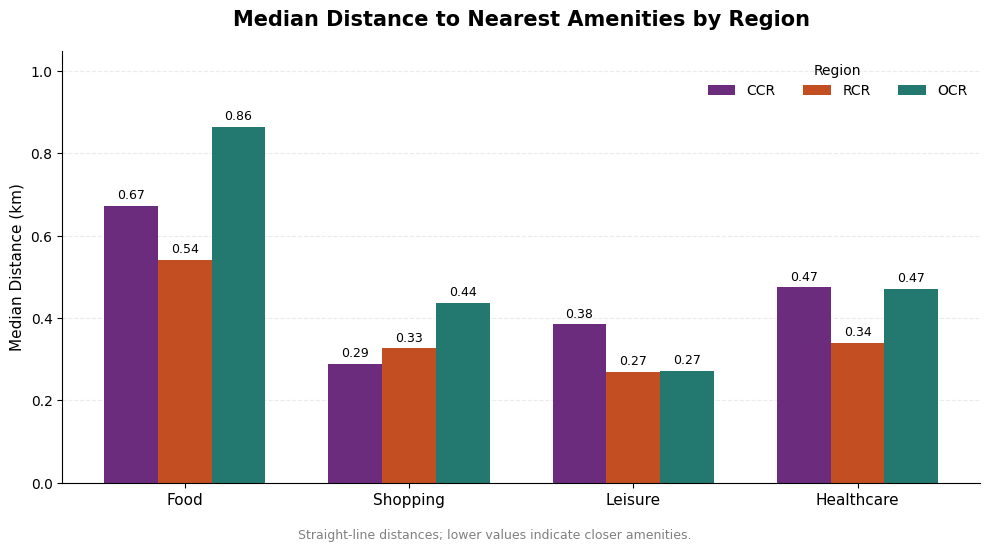

In [9]:



import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data from group GitHub
url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/amenities_median_distances_km.csv"

summary = pd.read_csv(url, index_col=0)


regions = ['CCR', 'RCR', 'OCR']
categories = ['Food', 'Shopping', 'Leisure', 'Healthcare']


# Chart settings
x = np.arange(len(categories))
width = 0.24

colors = {
    'CCR': '#6B2C7E',
    'RCR': '#C24E22',
    'OCR': '#23786F'
}

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, region in enumerate(regions):
    bars = ax.bar(
        x + (i - 1) * width,
        summary.loc[region].values,
        width,
        label=region,
        color=colors[region]
    )

    ax.bar_label(
        bars,
        fmt='%.2f',
        padding=3,
        fontsize=9
    )

ax.set_title(
    'Median Distance to Nearest Amenities by Region',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_ylabel('Median Distance (km)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)

ax.set_ylim(0, 1.05)
ax.legend(title='Region', frameon=False, ncol=3)

ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.figtext(
    0.5, 0.01,
    'Straight-line distances; lower values indicate closer amenities.',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save chart
plt.savefig(
    '/content/amenities_grouped_bar_chart.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    '/content/amenities_grouped_bar_chart.pdf',
    bbox_inches='tight'
)

**Key Findings**

- RCR has the shortest median distance to food and healthcare amenities.
- CCR performs best in shopping accessibility.
- RCR and OCR have almost identical access to parks.
- OCR has the longest median distance to hawker centres (0.87 km).